In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from imblearn.over_sampling import SMOTE

import shap

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("credit_card_fraud_10k.csv")

is_fraud
0    9849
1     151
Name: count, dtype: int64


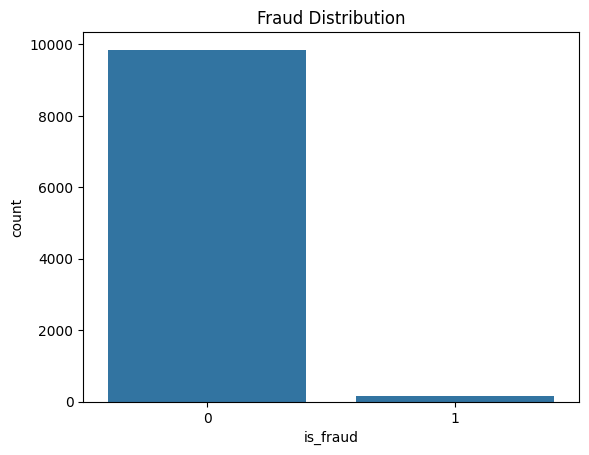

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df["is_fraud"].value_counts())

sns.countplot(x = "is_fraud", data = df)
plt.title("Fraud Distribution")
plt.show()

In [ ]:
X = df.drop("is_fraud", axis = 1)
y = df["is_fraud"]


In [ ]:
X = pd.get_dummies(
    X, columns = ["merchant_category"],
    drop_first = True
)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE
is_fraud
0    7880
1     120
Name: count, dtype: int64

After SMOTE
is_fraud
0    7880
1    7880
Name: count, dtype: int64


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report

svm = SVC(
    kernel = 'rbf',
    probability = True,
    class_weight = 'balanced',
    random_state = 42
)

svm.fit(X_train_smote, y_train_smote)

svm_pred = svm.predict(X_test_scaled)

print(classification_report(y_test, svm_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1969
           1       0.59      0.74      0.66        31

    accuracy                           0.99      2000
   macro avg       0.79      0.87      0.83      2000
weighted avg       0.99      0.99      0.99      2000



In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators = 200,
    max_depth = 5,
    learning_rate = 0.05,
    subsample = 0.8,
    colsample_bytree = 0.8,
    eval_metric = 'logloss',
    random_state = 42
)

xgb.fit(X_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
xgb_pred = xgb.predict(X_test_scaled)

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1969
           1       0.88      0.94      0.91        31

    accuracy                           1.00      2000
   macro avg       0.94      0.97      0.95      2000
weighted avg       1.00      1.00      1.00      2000



In [ ]:
from sklearn.metrics import roc_auc_score

xgb_prob = xgb.predict_proba(
    X_test_scaled
)[:,1]

auc = roc_auc_score(
    y_test,
    xgb_prob
)

print("ROC AUC =", auc)

ROC AUC = 0.9989514900309638


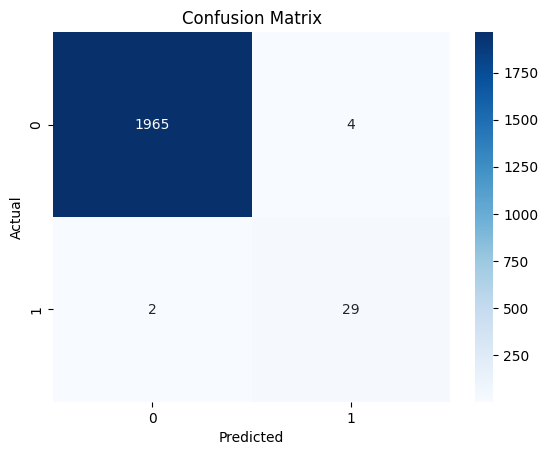

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    xgb_pred
)

sns.heatmap(
    cm,
    annot = True,
    fmt = 'd',
    cmap = 'Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
importance = pd.DataFrame({

    "Feature": X.columns,
    "Importance": xgb.feature_importances_

})

importance = importance.sort_values(
    by = "Importance",
    ascending=False
)

print(importance.head(10))

                          Feature  Importance
2                transaction_hour    0.312889
4               location_mismatch    0.177320
3             foreign_transaction    0.164487
5              device_trust_score    0.161032
6               velocity_last_24h    0.067217
11       merchant_category_Travel    0.025017
1                          amount    0.024803
9          merchant_category_Food    0.015425
10      merchant_category_Grocery    0.015186
8   merchant_category_Electronics    0.014749


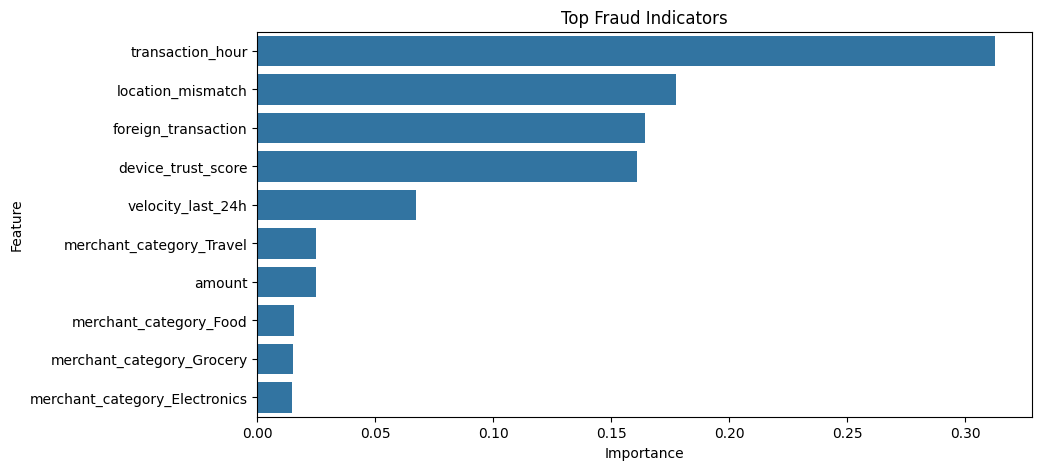

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=importance.head(10),
    x = "Importance",
    y = "Feature"
)

plt.title("Top Fraud Indicators")
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.1,0.2,0.3,0.4,0.5,0.6]:

    pred = (xgb_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        pred
    )

    recall = recall_score(
        y_test,
        pred
    )

    print(
        f"Threshold={threshold:.1f} "
        f"Precision={precision:.3f} "
        f"Recall={recall:.3f}"
    )

Threshold=0.1 Precision=0.500 Recall=0.968
Threshold=0.2 Precision=0.714 Recall=0.968
Threshold=0.3 Precision=0.833 Recall=0.968
Threshold=0.4 Precision=0.882 Recall=0.968
Threshold=0.5 Precision=0.879 Recall=0.935
Threshold=0.6 Precision=0.933 Recall=0.903


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

rf = RandomForestClassifier(
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

param_grid = {
    'n_estimators': [100],
    'max_depth': [5, 10],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1
)

grid_search.fit(
    X_train_smote,
    y_train_smote
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV ROC AUC:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}

Best CV ROC AUC:
0.999994589061564


In [ ]:
best_rf = grid_search.best_estimator_

rf_pred = best_rf.predict(X_test_scaled)

rf_prob = best_rf.predict_proba(X_test_scaled)[:, 1]

print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred))

rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC AUC =", rf_auc)

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1969
           1       0.77      0.74      0.75        31

    accuracy                           0.99      2000
   macro avg       0.88      0.87      0.88      2000
weighted avg       0.99      0.99      0.99      2000

Random Forest ROC AUC = 0.9934795786300562


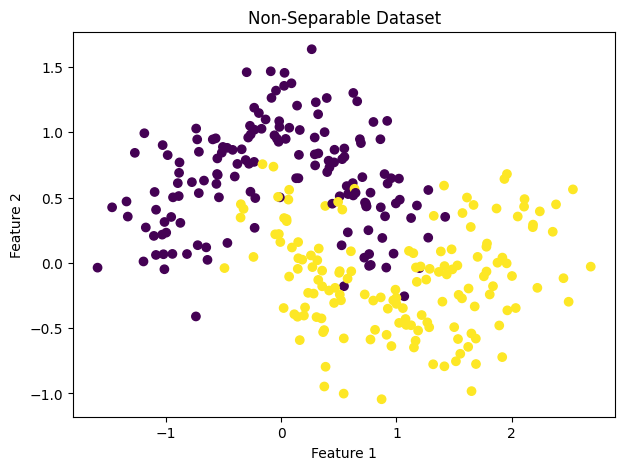

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.25,
    random_state=42
)

X_moon_train, X_moon_test, y_moon_train, y_moon_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42
)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Non-Separable Dataset")
plt.show()

In [ ]:
svm_moons = SVC(
    kernel='rbf',
    C=1,
    gamma='scale'
)

svm_moons.fit(
    X_moon_train,
    y_moon_train
)

moon_pred = svm_moons.predict(
    X_moon_test
)

print("SVM Classification Report:")
print(classification_report(
    y_moon_test,
    moon_pred
))

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.81      0.88        26
           1       0.87      0.97      0.92        34

    accuracy                           0.90        60
   macro avg       0.91      0.89      0.90        60
weighted avg       0.91      0.90      0.90        60



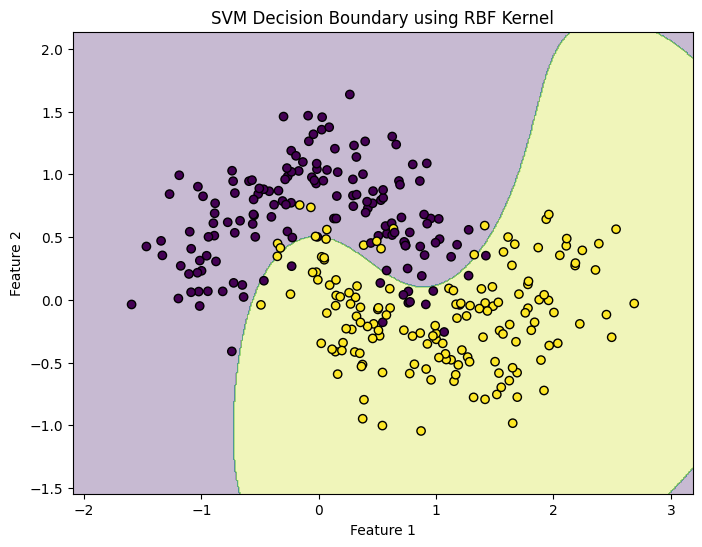

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x_min = X_moons[:, 0].min() - 0.5
x_max = X_moons[:, 0].max() + 0.5
y_min = X_moons[:, 1].min() - 0.5
y_max = X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = svm_moons.predict(grid)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3
)

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    edgecolors='k'
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("SVM Decision Boundary using RBF Kernel")

plt.show()

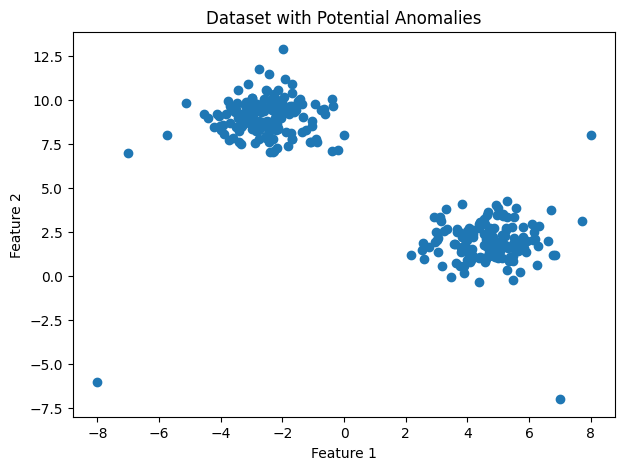

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture
import numpy as np
import matplotlib.pyplot as plt

X_gmm, y_gmm = make_blobs(
    n_samples=300,
    centers=2,
    cluster_std=1.0,
    random_state=42
)

anomalies = np.array([
    [8, 8],
    [-7, 7],
    [7, -7],
    [-8, -6],
    [0, 8]
])

X_gmm = np.vstack([
    X_gmm,
    anomalies
])

plt.figure(figsize=(7, 5))

plt.scatter(
    X_gmm[:, 0],
    X_gmm[:, 1]
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Dataset with Potential Anomalies")
plt.show()

In [ ]:
gmm = GaussianMixture(
    n_components=2,
    random_state=42
)

gmm.fit(X_gmm)

log_likelihood = gmm.score_samples(X_gmm)

print("Log-likelihood of first 10 points:")
print(log_likelihood[:10])

Log-likelihood of first 10 points:
[-3.27369225 -4.15243084 -3.13411231 -3.29237702 -4.44053112 -4.73106903
 -3.38750211 -4.21016247 -3.12006022 -4.35993133]


In [ ]:
threshold = np.percentile(
    log_likelihood,
    5
)

anomaly_labels = log_likelihood < threshold

print("Number of anomalies detected:",
      anomaly_labels.sum())

Number of anomalies detected: 16


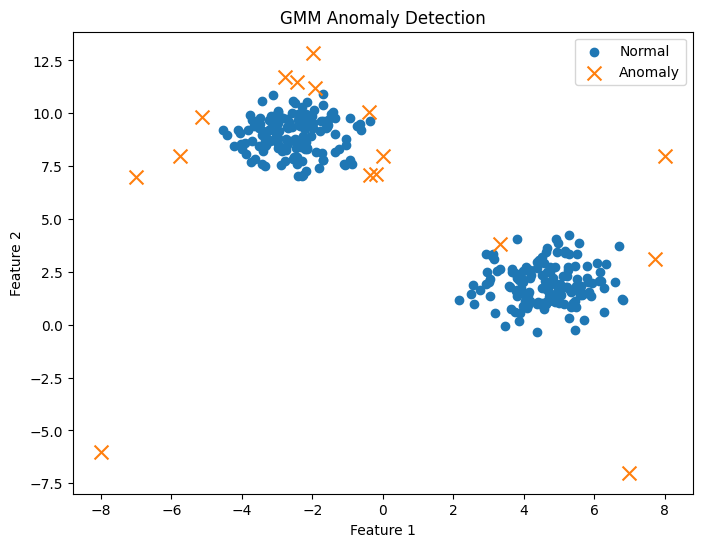

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_gmm[~anomaly_labels, 0],
    X_gmm[~anomaly_labels, 1],
    label="Normal"
)

plt.scatter(
    X_gmm[anomaly_labels, 0],
    X_gmm[anomaly_labels, 1],
    marker='x',
    s=100,
    label="Anomaly"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("GMM Anomaly Detection")
plt.legend()
plt.show()